# 05 A pretrained CNN: ResNet18

**Goal of this notebook.** Our best MLP reaches 45.5 % and cannot see shapes. Here we try a
**convolutional neural network (CNN)**. A CNN slides small filters over the image, so it finds local
patterns (edges, textures, brush strokes) wherever they are, and combines them into bigger shapes
layer after layer.

We do not train a CNN from zero: 1 061 images are far too few. We take **ResNet18**, a CNN of 18 layers
already trained on **ImageNet** (1.2 million photos of 1 000 kinds of objects), and we reuse what it
has learned. This is **transfer learning**. We compare two ways:

- **A. Feature extractor.** The ResNet stays frozen. It turns each painting into 512 numbers (its
  "features"), and we train only a small head on top: one `nn.Linear` layer (a *linear probe*) or a
  small MLP.
- **B. Fine-tuning.** We also retrain the last block of the ResNet (`layer4`), with data augmentation.

The ResNet comes from torchvision; the heads, the training loop, the freezing and the checks are ours.
Then we look for two silent failures, and we finally measure the **painter leakage** announced in
notebook 04. The test set stays locked.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedGroupKFold

from museum_guide.config import FAST_RUN, set_seed
from museum_guide.data import UNKNOWN_ARTIST, artist_groups, class_names, load_images, load_split_images
from museum_guide.evaluation import confusion_matrix, most_confused, per_class_report, save_results
from museum_guide.features import cached_features, extract_features
from museum_guide.models import ResNetClassifier, count_parameters, count_trainable, make_head
from museum_guide.plots import PALETTE, plot_confusion, plot_history, save_figure
from museum_guide.recipes import FINETUNE, train_finetune, train_head
from museum_guide.training import evaluate, fit, make_loaders, predict

set_seed()
SEEDS = [0] if FAST_RUN else [0, 1, 2]
loss_fn = nn.CrossEntropyLoss()

images, meta = load_split_images(224)  # uint8 images, 224 x 224, train and validation only
classes = class_names(meta)
y_all = torch.tensor(meta["label_idx"].to_numpy())
is_train = torch.from_numpy(meta["split"].to_numpy() == "train")
is_val = torch.from_numpy(meta["split"].to_numpy() == "val")
print("train", tuple(images["train"][0].shape), "| validation", tuple(images["val"][0].shape), "| seeds", SEEDS)

train (1061, 3, 224, 224) | validation (219, 3, 224, 224) | seeds [0, 1, 2]


## 1. The pretrained network

**What we do.** We load ResNet18 with its ImageNet weights, replace its last layer (1 000 ImageNet
classes) by our head (5 styles), and count the parameters that each method trains.

In [2]:
frozen = ResNetClassifier(train_from=None)
finetuned = ResNetClassifier(train_from="layer4")
sizes = {"ResNet18 + linear head (total)": count_parameters(frozen),
         "trained by A (feature extractor + linear head)": count_trainable(frozen),
         "trained by B (fine-tuning of layer4 + head)": count_trainable(finetuned)}
pd.Series(sizes, name="parameters").to_frame()

,parameters
ResNet18 + linear head (total),11179077
trained by A (feature extractor + linear head),2565
trained by B (fine-tuning of layer4 + head),8396293


**What we see.** ResNet18 has 11.2 million parameters, but method A trains only **2 565** of them (the
linear head): fewer than our smallest MLP (0.5 million). Method B trains 8.4 million (75 % of the
network), so it needs much more computing time and it can overfit more easily.

## 2. Method A: frozen features and a small head

**What we do.** We pass every painting once through the frozen ResNet (evaluation mode, ImageNet
normalisation) and keep its 512 features. This is done once and saved, so training a head then takes
seconds. We train two heads with our training loop (AdamW, early stopping on the validation loss),
with 3 seeds each:

- a **linear probe**: one `nn.Linear(512, 5)`, 2 565 parameters;
- a **small MLP head**: 512 -> 256 -> 5 with ReLU and dropout 0.5.

In [3]:
features, seconds_per_image = cached_features(meta)
F_train, y_train = features[is_train], y_all[is_train]
F_val, y_val = features[is_val], y_all[is_val]
print(f"features: {tuple(features.shape)}, {seconds_per_image * 1000:.1f} ms per image (batches of 64, "
      f"{torch.get_num_threads()} CPU threads)")

heads = {"linear probe": dict(hidden=()), "MLP head": dict(hidden=(256,), dropout=0.5)}
rows, head_models = [], {}
for name, cfg in heads.items():
    for seed in SEEDS:
        model, h = train_head(F_train, y_train, F_val, y_val, seed=seed, **cfg)
        loaders_f = make_loaders(F_train, y_train, F_val, y_val)
        train_acc = evaluate(model, loaders_f.train_eval, loss_fn)[1]
        val_loss, val_acc = evaluate(model, loaders_f.val, loss_fn)
        rows.append({"head": name, "seed": seed, "val_acc": val_acc, "gap": train_acc - val_acc,
                     "val_loss": val_loss, "epochs": len(h["val_loss"]),
                     "trained_parameters": count_parameters(model), "seconds": sum(h["epoch_time"])})
        if seed == 0:
            head_models[name] = (model, h)
head_runs = pd.DataFrame(rows)
head_table = head_runs.groupby("head", sort=False).agg(
    val_acc=("val_acc", "mean"), val_acc_std=("val_acc", "std"), gap=("gap", "mean"),
    val_loss=("val_loss", "mean"), epochs=("epochs", "mean"), trained_parameters=("trained_parameters", "first"),
    seconds=("seconds", "mean"))
head_table.round(3)

features: (1500, 512), 15.5 ms per image (batches of 64, 8 CPU threads)


,val_acc,val_acc_std,gap,val_loss,epochs,trained_parameters,seconds
head,,,,,,,
linear probe,0.881,0.000,0.087,0.419,36.000,2565,0.371
MLP head,0.892,0.011,0.098,0.370,27.667,132613,0.521


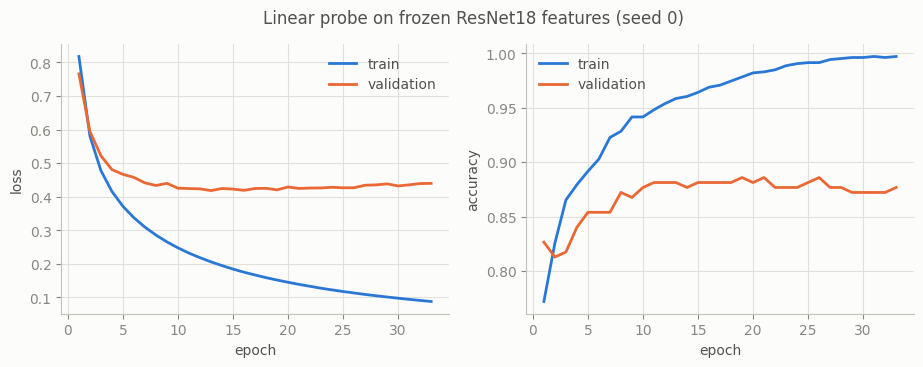

In [4]:
plot_history(head_models["linear probe"][1], "Linear probe on frozen ResNet18 features (seed 0)",
             save_as="05_linear_probe_curves")

**What we see.** The jump is huge. The **linear probe** reaches **88.1 %** on validation, against
45.5 % for our best MLP on pixels. The 3 seeds give the same result: with fixed features, the training
always finds the same solution. The **MLP head** reaches 89.2 % (standard deviation 1.1 points), the
same within the noise, with 50 times more parameters.

The gap between train and validation stays small (0.09 to 0.10). The validation loss stops improving
after 10 to 15 epochs, and early stopping keeps the model there. Training a head takes less than a
second (0.4 s for the linear probe) once the features are computed; computing the features takes
15.5 ms per painting on this laptop CPU (in batches of 64).

Why it works: on ImageNet, the ResNet learned to detect edges, textures, patterns and parts of objects.
These features describe a painting much better than raw pixels, so a straight line (a linear model)
between the 5 styles is enough. Our MLP becomes useful again, as a head on top of good features.

## 3. Two silent failures of feature extraction

**What we do.** Two mistakes are easy to make when we extract features, and nothing crashes. We make
each one on purpose, train the same linear probe (seed 0), and measure the damage.

1. **Forgetting `model.eval()`.** In training mode, each batch norm layer of the ResNet normalises
   with the mean and variance **of the current batch** instead of the statistics learned on ImageNet.
   Our images are stored in order of style, so a batch of 64 holds mostly one style.
2. **Forgetting the ImageNet normalisation.** We give the pixels in [0, 1] without
   $(x - \text{mean}) / \text{std}$, so the inputs are not on the scale the ResNet was trained with.

In [5]:
all_images = load_images(meta, 224)
naive = ResNetClassifier(train_from=None)
naive.backbone.train()  # the mistake: model.eval() is never called
features_train_mode = extract_features(naive, all_images)
features_no_norm, _ = cached_features(meta, name="resnet18_no_normalisation", normalise=False)

bugs = {}
for name, F in (("correct (eval mode, ImageNet normalisation)", features),
                ("forgot model.eval()", features_train_mode),
                ("forgot the ImageNet normalisation", features_no_norm)):
    model, h = train_head(F[is_train], y_train, F[is_val], y_val, seed=0)
    bugs[name] = evaluate(model, make_loaders(F[is_train], y_train, F[is_val], y_val).val, loss_fn)[1]
pd.Series(bugs, name="validation accuracy").to_frame().round(3)

,validation accuracy
"correct (eval mode, ImageNet normalisation)",0.881
forgot model.eval(),0.128
forgot the ImageNet normalisation,0.817


**What we see.**

- **Forgetting `model.eval()` is a disaster: 12.8 %**, worse than always giving the same answer
  (22.8 %). In training mode, batch norm normalises each batch with its own mean. Our batches hold
  mostly one style, so this removes exactly what the paintings of a batch share: their style. On a
  kiosk that handles one photo at a time, the "statistics" of a batch of one image would make no
  sense at all.
- **Forgetting the ImageNet normalisation costs 6.4 points** (81.7 % instead of 88.1 %). The network
  still works, but its inputs are not on the scale it was trained with.

Neither mistake crashes or prints a warning. Only a measured comparison reveals them.

## 4. Method B: fine-tuning the last block

**What we do.** Now the last block of the ResNet (`layer4`) learns too. The earlier blocks stay
frozen, and their batch norm layers stay in evaluation mode (our `ResNetClassifier` takes care of it).
Because many more weights now learn from only 1 061 images, we add **data augmentation**: at each
epoch every training image gets a random crop (60 to 100 % of its area, resized back to 224 x 224) and
a random left-right flip.

The pretrained block gets a small learning rate, so that its ImageNet knowledge is adapted, not erased.
Settings: AdamW with a learning rate of 0.0001 for `layer4` and 0.001 for the new head, weight decay
0.01, batches of 32 images, a cosine schedule over 10 epochs and early stopping (patience 3). Each epoch
passes all the images through the whole ResNet, so this is the slowest part of the project on a CPU.

In [6]:
loaders_img = make_loaders(*images["train"], *images["val"], batch_size=32, eval_batch_size=128)
FT_SEEDS = SEEDS
rows, ft_models = [], {}
for seed in FT_SEEDS:
    cfg = dict(FINETUNE, epochs=2) if FAST_RUN else FINETUNE
    model, h = train_finetune(loaders_img, seed=seed, **cfg)
    train_acc = evaluate(model, loaders_img.train_eval, loss_fn)[1]
    val_loss, val_acc = evaluate(model, loaders_img.val, loss_fn)
    rows.append({"seed": seed, "val_acc": val_acc, "gap": train_acc - val_acc, "val_loss": val_loss,
                 "epochs": len(h["val_loss"]), "best_epoch": int(np.argmin(h["val_loss"])) + 1,
                 "minutes": sum(h["epoch_time"]) / 60})
    ft_models[seed] = (model, h)
ft_runs = pd.DataFrame(rows).set_index("seed")
print("trained parameters:", count_trainable(ft_models[FT_SEEDS[0]][0]))
ft_runs.round(3)

trained parameters: 8396293


,val_acc,gap,val_loss,epochs,best_epoch,minutes
seed,,,,,,
0,0.858,0.124,0.384,6,3,2.232
1,0.849,0.149,0.453,10,7,3.563
2,0.854,0.092,0.399,5,2,1.747


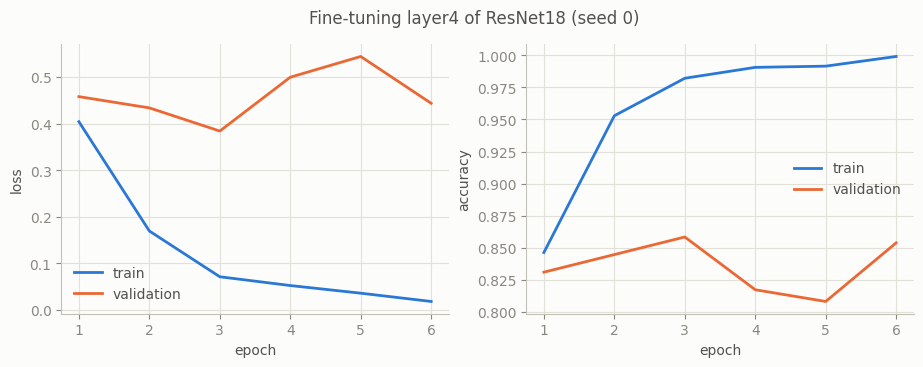

In [7]:
plot_history(ft_models[FT_SEEDS[0]][1], "Fine-tuning layer4 of ResNet18 (seed 0)", save_as="05_finetune_curves")

**What we see.** Fine-tuning reaches **85.4 %** on average (85.8, 84.9 and 85.4 % for the 3 seeds).
This is **below** the linear probe (88.1 %).

The curves show why. The training accuracy climbs to 99.9 %, while the best validation loss comes
early (epoch 2 to 7) and then rises. With 8.4 million weights learning from 1 061 images, the network
starts to memorise, even with augmentation. It is also much more expensive: 1.7 to 3.6 minutes of
training per seed, against 0.4 s for the linear probe.

So with this amount of data, the frozen features are both better and cheaper. Fine-tuning would
probably win with many more paintings per style.

## 5. Measuring the painter leakage

**What we do.** In notebook 01 we split the data so that a known painter never appears in two parts.
Does it matter? To measure it fairly, we must score **the same images** in two situations, and change
only one thing: whether the model has seen other paintings by the same painter.

We use 5-fold **cross-validation** on the training and validation images (1 280 paintings; the test
set stays locked). The images are cut into 5 groups; we train on 4 groups and predict the 5th, five
times, so that every image gets exactly one prediction from a model that never saw it.

- **Random folds**: the groups ignore the painters, so the other paintings of a painter are usually in
  the training groups.
- **Painter folds**: all the paintings of a known painter are in the same group, so the model has
  never seen that painter.

We use the linear probe (15 epochs per fold, no early stopping) and 3 different random cuts. We score
separately the images by **known painters** (where leakage is possible) and by "Unknown Artist" (a
control group: grouping changes nothing for them).

In [8]:
keep = (meta["split"] != "test").to_numpy()
m_cv = meta[keep].reset_index(drop=True)
F_cv, y_cv = features[torch.tensor(keep)], y_all[torch.tensor(keep)]
known = (m_cv["artist"] != UNKNOWN_ARTIST).to_numpy()


def out_of_fold_correct(groups, seed, epochs=15):
    """True/False for each image: is the prediction of the fold model that never saw it correct?"""
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    pred = torch.empty_like(y_cv)
    for tr, te in cv.split(np.zeros(len(y_cv)), y_cv.numpy(), groups):
        tr, te = torch.from_numpy(tr), torch.from_numpy(te)
        torch.manual_seed(seed)
        head = make_head(F_cv[tr])
        optimizer = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-2)
        fit(head, optimizer, make_loaders(F_cv[tr], y_cv[tr], F_cv[te], y_cv[te]), epochs, seed=seed + 1)
        pred[te] = predict(head, make_loaders(F_cv[te], y_cv[te], F_cv[te], y_cv[te]).val)[0].argmax(dim=1)
    return (pred == y_cv).numpy()


rows = []
for seed in SEEDS:
    for folds, groups in (("random folds", m_cv["id"].to_numpy()), ("painter folds", artist_groups(m_cv))):
        ok = out_of_fold_correct(groups, seed)
        rows.append({"folds": folds, "seed": seed, "all images": ok.mean(),
                     "known painters": ok[known].mean(), "unknown painters": ok[~known].mean()})
leak_runs = pd.DataFrame(rows)
leak_table = leak_runs.groupby("folds", sort=False)[["all images", "known painters", "unknown painters"]].agg(["mean", "std"])
print(f"{known.sum()} images by known painters, {(~known).sum()} by unknown painters")
leak_table.round(3)

536 images by known painters, 744 by unknown painters


all images        known painters        unknown painters       
                    mean    std           mean    std             mean    std
folds                                                                        
random folds       0.842  0.004          0.837  0.005            0.846  0.003
painter folds      0.793  0.003          0.723  0.008            0.844  0.002

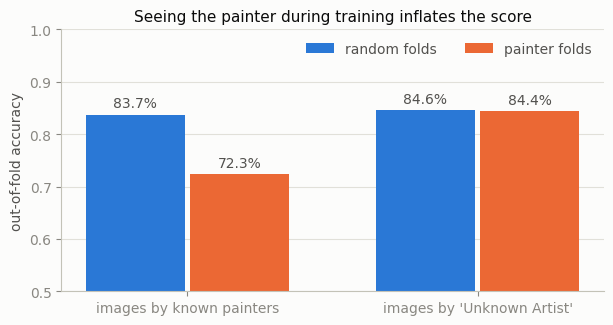

In [9]:
means = leak_runs.groupby("folds", sort=False)[["known painters", "unknown painters"]].mean()
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(2)
for k, (folds, color) in enumerate(zip(means.index, PALETTE)):
    bars = ax.bar(x + (k - 0.5) * 0.36, means.loc[folds], width=0.34, color=color, label=folds)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in means.loc[folds]], padding=3, color="#52514e")
ax.set_xticks(x, ["images by known painters", "images by 'Unknown Artist'"])
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("out-of-fold accuracy")
ax.set_title("Seeing the painter during training inflates the score")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncol=2)
save_figure(fig, "05_painter_leakage")
plt.show()

**What we see.** On the images by **known painters**, the same model scores **83.7 %** with random
folds but only **72.3 %** with painter folds. Seeing other paintings by the same painter during
training adds **11.4 points** to the score.

On the control group ("Unknown Artist"), the two kinds of folds give the same score (84.6 % and
84.4 %). The difference is not luck (the standard deviations are below 1 point over 3 random cuts),
and it does not come from the folds themselves: it comes from the painter.

So the model partly recognises **painters**, not only styles. A random split would give a score that
is too optimistic for the museum, whose visitors will photograph paintings that are not in our data.
This is why our split keeps each known painter in one part (notebook 01). We cannot do the same for the
"Unknown Artist" images, so our scores may still be a little optimistic: a limit to remember.

## 6. Which paintings does the ResNet get wrong?

**What we do.** As for the MLP in notebook 03, we look at the confusion matrix of the linear probe
(seed 0) on the validation images.

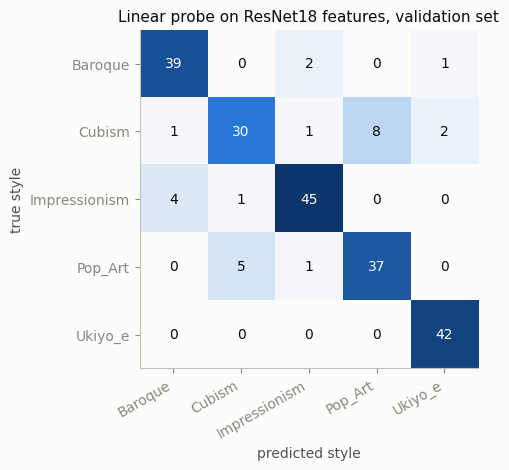

most frequent mistakes (true -> predicted, count): [('Cubism', 'Pop_Art', 8), ('Pop_Art', 'Cubism', 5), ('Impressionism', 'Baroque', 4)]


,recall,precision,f1,images
Baroque,0.929,0.886,0.907,42
Cubism,0.714,0.833,0.769,42
Impressionism,0.900,0.918,0.909,50
Pop_Art,0.860,0.822,0.841,43
Ukiyo_e,1.000,0.933,0.966,42


In [10]:
probe = head_models["linear probe"][0]
logits, y_true = predict(probe, make_loaders(F_train, y_train, F_val, y_val).val)
cm = confusion_matrix(y_true, logits.argmax(dim=1), len(classes))
plot_confusion(cm, classes, "Linear probe on ResNet18 features, validation set", save_as="05_confusion_probe")
report = per_class_report(cm, classes)
print("most frequent mistakes (true -> predicted, count):", most_confused(cm, classes))
report.round(3)

**What we see.** The linear probe makes 26 mistakes on 219 paintings, against 118 for the best MLP
(notebook 03).

- **Ukiyo-e** is always found (recall 100 %), **Baroque** and **Impressionism** about 9 times out of 10.
- **Cubism** is still the hardest style (recall 71 %), but it is no longer invisible: the MLP found 7 %.
- The most frequent confusion is **Cubism and Pop Art**, in both directions (8 and 5 paintings). Both
  use flat areas of strong colour and hard edges.

In [11]:
save_results("05_resnet", {
    "parameters": sizes, "feature_ms_per_image_batch64": seconds_per_image * 1000,
    "heads": head_table.reset_index().to_dict(orient="records"), "head_runs": head_runs.to_dict(orient="records"),
    "extraction_bugs": bugs,
    "finetune_recipe": {k: v for k, v in FINETUNE.items()}, "finetune_runs": ft_runs.reset_index().to_dict(orient="records"),
    "leakage": leak_runs.to_dict(orient="records"),
    "probe_seed0_per_class": report.reset_index(names="style").to_dict(orient="records"),
    "probe_seed0_most_confused": most_confused(cm, classes),
})

WindowsPath('C:/Users/benca/OneDrive - Thelio/Documents/Perso/Albert School/Deep learning/neural-network-project/reports/results/05_resnet.json')

## What we learned

- **Transfer learning changes everything**: 88.1 % with only 2 565 trained parameters (linear probe on
  frozen ResNet18 features), against 45.5 % for our best MLP on pixels. A small MLP head gives 89.2 %,
  the same within the noise.
- **Fine-tuning is slower and not better here** (85.4 %): too many weights for 1 061 images.
- **Two silent bugs**: without `model.eval()` the features become useless (12.8 %); without the
  ImageNet normalisation we lose 6.4 points.
- **Painter leakage is real**: +11.4 points on the images by known painters when the painter was seen
  in training, and no change on the control group. Our split by painter is necessary.

**Next step** (notebook 06): classical models (logistic regression, random forest) on pixels, colour
features and ResNet features, the speed on a kiosk CPU, the final test (measured once), and our
recommendation to the director.